In [2]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Добавляем корень проекта в пути, чтобы Jupyter видел папку src
sys.path.append(os.path.abspath('..'))

from src.data.db import get_db_engine

# Настройки отображения
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Красивые графики в стиле Seaborn
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)

print("✅ Библиотеки успешно импортированы и настроены!")

✅ Библиотеки успешно импортированы и настроены!


In [3]:
# Подключаемся к базе данных
engine = get_db_engine()

# Загружаем данные
query = """
    SELECT * FROM afrr_prices 
    ORDER BY datetime ASC
"""
df = pd.read_sql(query, engine, parse_dates=['datetime'])

# Делаем datetime индексом для удобства работы с временными рядами
df.set_index('datetime', inplace=True)

print(f"✅ Данные успешно загружены!")
print(f"📊 Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
print(f"📅 Период: с {df.index.min()} по {df.index.max()}")
print("\nПервые 5 строк:")
display(df.head())

✅ Данные успешно загружены!
📊 Размер датасета: 26304 строк, 8 колонок
📅 Период: с 2023-01-01 00:00:00+00:00 по 2025-12-31 23:00:00+00:00

Первые 5 строк:


,consumption,wind,solar,nuclear,temperature,exchange_net_export,carbon_intensity_production,target_vwap_up
datetime,,,,,,,,
2023-01-01 00:00:00+00:00,3849.30,124.03,0.00,1900.00,5.23,-900.00,None,0.00
2023-01-01 01:00:00+00:00,3625.20,119.20,0.00,1900.00,5.30,-702.10,None,0.00
2023-01-01 02:00:00+00:00,3442.88,121.98,0.00,1900.00,4.91,-540.60,None,0.00
2023-01-01 03:00:00+00:00,3397.08,125.50,0.00,1900.00,4.51,-900.00,None,0.00
2023-01-01 04:00:00+00:00,3442.40,126.23,0.00,1900.00,4.51,-721.30,None,0.00


## 1. Первичный обзор данных

Нам удалось успешно подключиться к базе данных и загрузить таблицу `afrr_prices`. 

**Ключевые факты о датасете:**
* **Объем:** 26 304 строки. Это ровно 3 полных года (2023, 2024, 2025) с часовым разрешением (24 часа × 365 дней × 3 года + 1 день високосного 2024 года). Пропущенных часов нет.
* **Временной промежуток:** с `1 января 2023` по `31 декабря 2025`. Время указано в UTC.
* **Признаки:** 7 прогнозных признаков (потребление, ветер, солнце, АЭС, температура, экспорт, углеродный след) и 1 целевая переменная (`target_vwap_up`).

**Предварительные наблюдения (по первым строкам):**
1. Целевая переменная `target_vwap_up` часто равна `0.0`. Это означает, что в эти часы на рынке не было активаций. Это **ключевая особенность** задачи: данные сильно "разряжены" (sparse), и простая линейная регрессия может с этим не справиться.
2. В колонке `carbon_intensity_production` видны значения `None` (пропуски). Нам нужно будет проверить, это единичные пропуски или вся колонка пустая.

In [4]:
# 1. Информация о типах данных и пропусках
print("=" * 50)
print("ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ:")
print("=" * 50)
df.info()

print("\n" + "=" * 50)
print("КОЛИЧЕСТВО ПРОПУСКОВ ПО КОЛОНКАМ:")
print("=" * 50)
display(df.isna().sum().to_frame(name='Пропуски'))

print("\n" + "=" * 50)
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА (min, max, среднее):")
print("=" * 50)
display(df.describe().T)

ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ:
<class 'pandas.DataFrame'>
DatetimeIndex: 26304 entries, 2023-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   consumption                  26304 non-null  float64
 1   wind                         26304 non-null  float64
 2   solar                        26304 non-null  float64
 3   nuclear                      26304 non-null  float64
 4   temperature                  26304 non-null  float64
 5   exchange_net_export          26304 non-null  float64
 6   carbon_intensity_production  0 non-null      object 
 7   target_vwap_up               26304 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.8+ MB

КОЛИЧЕСТВО ПРОПУСКОВ ПО КОЛОНКАМ:


,Пропуски
consumption,0
wind,0
solar,0
nuclear,0
temperature,0
exchange_net_export,0
carbon_intensity_production,26304
target_vwap_up,0



ОПИСАТЕЛЬНАЯ СТАТИСТИКА (min, max, среднее):


,count,mean,std,min,25%,50%,75%,max
consumption,26304.00,4892.35,824.54,2342.18,4266.62,4827.59,5445.61,7336.58
wind,26304.00,67.77,62.83,0.55,17.65,48.04,99.25,298.60
solar,26304.00,614.15,901.69,0.00,0.00,30.09,1045.03,4179.00
nuclear,26304.00,1731.61,236.13,956.00,1428.00,1900.00,1900.00,1949.50
temperature,26304.00,12.53,9.21,-7.29,4.85,12.14,19.76,35.91
exchange_net_export,26304.00,-1130.76,1227.78,-5365.30,-1988.33,-1300.00,-436.25,3819.90
target_vwap_up,26304.00,23.44,44.14,0.00,1.02,3.86,21.75,213.75


## 2. Анализ типов данных и пропусков (включая проверку оригинала)

**Проверка оригинального CSV:**
Была проведена сверка с исходным файлом `hu_afrr_up_2023_2025.csv`. Оказалось, что колонка `carbon_intensity_production` **изначально пуста** во всем датасете (26304 пропуска из 26304). 

*Колонка `target_vwap_up` и остальные 6 признаков заполнены на 100%.*

**Решение:** Признак `carbon_intensity_production` исключен из дальнейшего анализа, так как не содержит информации. Если руководитель предоставит эти данные позже, мы вернем их в модель.

✅ Колонка удалена. Осталось колонок: 7

📊 Статистика по target_vwap_up:
   Минимум:  0.00 €/МВт·ч
   Максимум: 213.75 €/МВт·ч
   Среднее:  23.44 €/МВт·ч
   Медиана:  3.86 €/МВт·ч

⚠️ Доля часов, где цена равна 0 (нет активаций): 11.04%


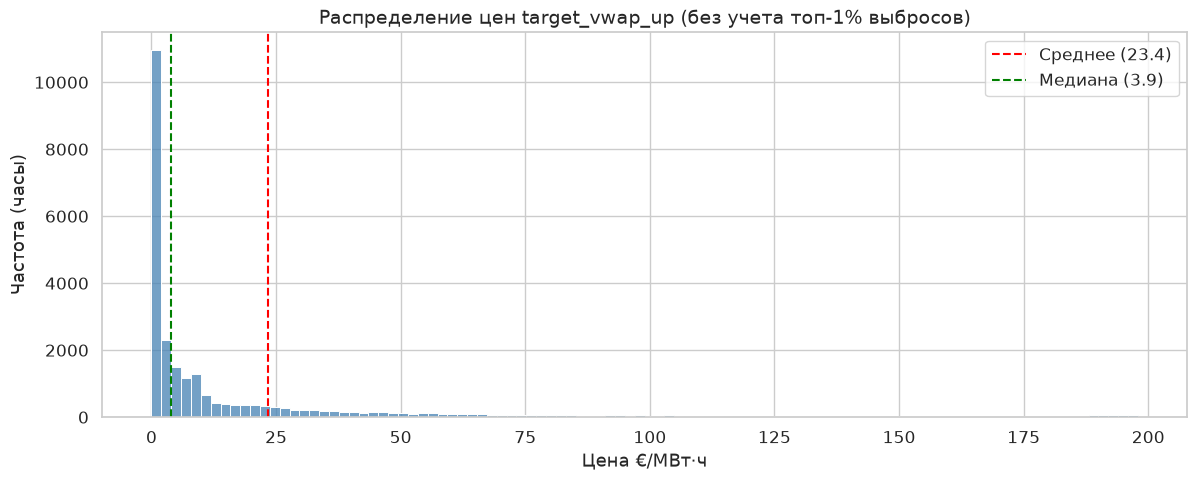

In [6]:
# 1. Удаляем пустую колонку
df = df.drop(columns=['carbon_intensity_production'])
print(f"✅ Колонка удалена. Осталось колонок: {df.shape[1]}")

# 2. Смотрим на распределение целевой переменной
target = df['target_vwap_up']
print(f"\n📊 Статистика по target_vwap_up:")
print(f"   Минимум:  {target.min():.2f} €/МВт·ч")
print(f"   Максимум: {target.max():.2f} €/МВт·ч")
print(f"   Среднее:  {target.mean():.2f} €/МВт·ч")
print(f"   Медиана:  {target.median():.2f} €/МВт·ч")

# 3. Считаем долю нулей
zero_pct = (target == 0).mean() * 100
print(f"\n⚠️ Доля часов, где цена равна 0 (нет активаций): {zero_pct:.2f}%")

# 4. Строим график
plt.figure(figsize=(14, 5))
sns.histplot(target[target < target.quantile(0.99)], bins=100, color='steelblue')
plt.title('Распределение цен target_vwap_up (без учета топ-1% выбросов)', fontsize=14)
plt.xlabel('Цена €/МВт·ч')
plt.ylabel('Частота (часы)')
plt.axvline(target.mean(), color='red', linestyle='--', label=f'Среднее ({target.mean():.1f})')
plt.axvline(target.median(), color='green', linestyle='--', label=f'Медиана ({target.median():.1f})')
plt.legend()
plt.show()

## 3. Анализ целевой переменной (target_vwap_up)

Мы проанализировали распределение целевой переменной. Полученные метрики раскрывают ключевую специфику рынка:

* **Нулевые активации:** В **11.04%** случаев (почти каждый 9-й час) цена равна нулю. Это означает, что в эти часы рынок не проводил активаций вверх (UP). 
* **Сильная правосторонняя асимметрия (skewness):** Медиана составляет всего **3.86 €/МВт·ч**, в то время как среднее значение — **23.44 €/МВт·ч**. 
* **Выбросы:** Максимальная зафиксированная цена — **213.75 €/МВт·ч**. Это редкие, но очень высокие ценовые скачки (spikes).

**Что это значит для ML-модели?**
1. **Метрика:** Использовать MSE/RMSE будет **плохой идеей**, так как модель будет слишком сильно штрафоваться за редкие скачки и может начать «сглаживать» прогноз. Нам стоит ориентироваться на **MAE (Mean Absolute Error)**, которая более устойчива к выбросам и нулям.
2. **Подход к прогнозированию:** Из-за того, что 11% времени цена равна нулю, возможно, нам придется разбить задачу на два этапа: 
   * Классификация (будет ли активация вообще, или цена = 0).
   * Регрессия (если активация есть, то какая цена).
3. **Трансформация:** Из-за сильного перекоса вправо, возможно, стоит попробовать логарифмирование таргета (`log1p`), но с осторожностью из-за нулей.

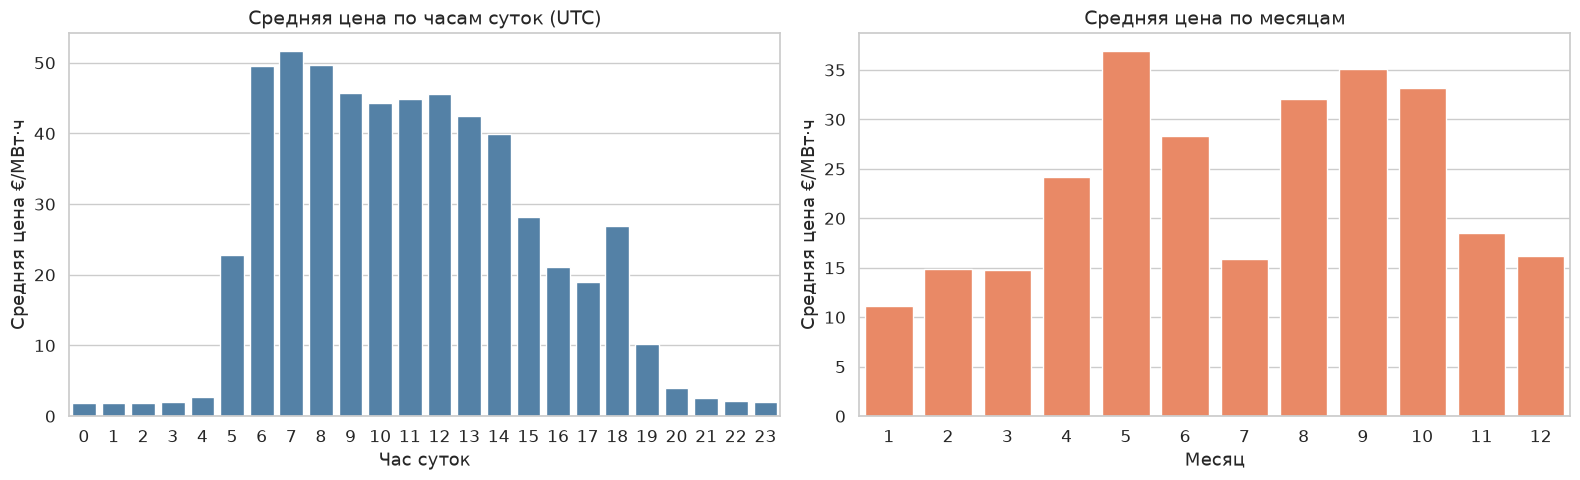

In [7]:
# Создаем датафрейм для анализа сезонности
df_time = df.copy()
df_time['hour'] = df_time.index.hour
df_time['dayofweek'] = df_time.index.dayofweek
df_time['month'] = df_time.index.month

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# График 1: Средняя цена по часам суток
sns.barplot(data=df_time, x='hour', y='target_vwap_up', ax=axes[0], 
            color='steelblue', errorbar=None)
axes[0].set_title('Средняя цена по часам суток (UTC)', fontsize=14)
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Средняя цена €/МВт·ч')

# График 2: Средняя цена по месяцам
sns.barplot(data=df_time, x='month', y='target_vwap_up', ax=axes[1], 
            color='coral', errorbar=None)
axes[1].set_title('Средняя цена по месяцам', fontsize=14)
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Средняя цена €/МВт·ч')

plt.tight_layout()
plt.show()

## 4. Анализ сезонности (Время)

Графики сезонности выявили ярко выраженные паттерны, которые станут отличными предикторами для нашей модели:

### 🕒 Суточная сезонность (по часам UTC)
* **"Мертвая зона" (00:00 – 04:00 UTC):** Цена практически равна нулю (около 1–2 €). Это ночные часы, когда потребление минимально.
* **Резкий утренний скачок (05:00 – 06:00 UTC):** Цена взлетает с 2 € до 50 €. Это момент, когда просыпается промышленность и начинается утренний пик потребления.
* **Плато (06:00 – 14:00 UTC):** Держится высокая цена (40–50 €/МВт·ч). Это рабочий день, максимальная нагрузка на сеть.
* **Вечерний спад:** После 15:00 цена начинает плавно снижаться, возвращаясь к ночным минимумам к 22:00 UTC.
* **Вывод для ML:** Признак "час суток" (hour) будет **критически важным**. Особенно важно создать бинарный признак "ночь/день" или использовать циклическое кодирование времени (синус/косинус).

### 📅 Месячная сезонность
* **Пики:** Май (почти 40 €) и осенний период: Сентябрь-Октябрь (около 35 €). 
* **Минимумы:** Январь (11 €) и летние месяцы (Июль — 16 €). 
* **Интересный факт:** На первый взгляд это может показаться контринтуитивным (обычно зимой цена выше из-за отопления). Но на рынке *capacity* (резервов мощности) логика может быть иной: возможно, в мае/сентябре происходят плановые ремонты сетей, что создает дефицит резервов и взвинчивает цены.
* **Вывод для ML:** Месяц (month) и время года тоже нужно обязательно добавлять в признаки.

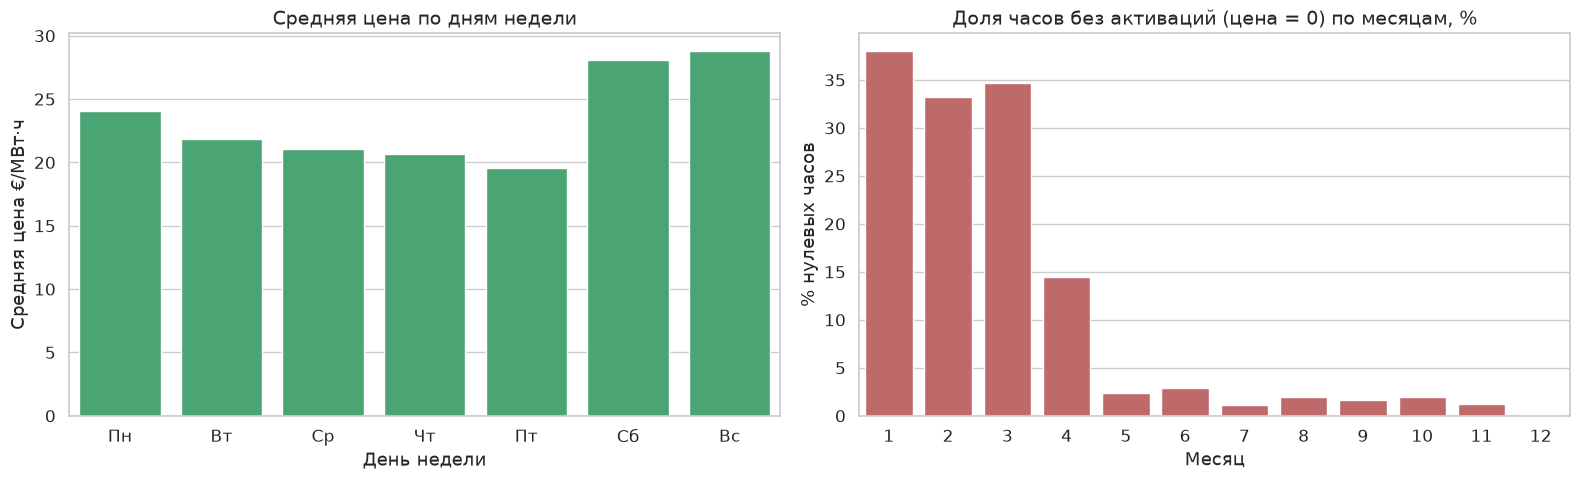

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# График 1: Средняя цена по дням недели
days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
sns.barplot(data=df_time, x='dayofweek', y='target_vwap_up', ax=axes[0], 
            color='mediumseagreen', errorbar=None)
axes[0].set_xticklabels(days)
axes[0].set_title('Средняя цена по дням недели', fontsize=14)
axes[0].set_xlabel('День недели')
axes[0].set_ylabel('Средняя цена €/МВт·ч')

# График 2: Доля нулевых активаций по месяцам
df_time['is_zero'] = (df_time['target_vwap_up'] == 0)
zero_by_month = df_time.groupby('month')['is_zero'].mean() * 100
sns.barplot(x=zero_by_month.index, y=zero_by_month.values, ax=axes[1], 
            color='indianred')
axes[1].set_title('Доля часов без активаций (цена = 0) по месяцам, %', fontsize=14)
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('% нулевых часов')

plt.tight_layout()
plt.show()

## 5. Анализ дней недели и нулевых активаций

### 🗓 Дни недели
* **Аномалия выходных:** Вопреки классической логике рынков *электроэнергии* (где в выходные потребление падает), на рынке *AFRR capacity* цена в субботу и воскресенье **выше** (около 28 €/МВт·ч), чем в будние дни (19–24 €).
* **Гипотеза:** В выходные промышленность останавливается, но энергосистема все еще требует резервов на случай аварий, при этом предложение (генерация) может быть менее гибким. Либо это специфика венгерского рынка.
* **Вывод для ML:** Признак "день недели" (dayofweek) и бинарный флаг "выходной" (is_weekend) обязательно добавятся в модель.

### 0️⃣ Доля нулевых активаций
* **Зимний феномен:** С января по март доля часов, где цена равна 0, составляет огромные **33–37%**. В это время года система, вероятно, настолько перегружена, что рыночные механизмы активации вверх не срабатывают, либо цена ограничивается регулятором.
* **Летне-осенняя стабильность:** С апреля по декабрь нулевых активаций почти нет (1–3%). В этот период рынок работает в обычном режиме.
* **Вывод для ML:** Это **критически важный инсайт**. Признак "месяц" и сезон года помогут модели понять, когда ожидать структурные нули. Возможно, придется обучать отдельную модель для зимнего периода.

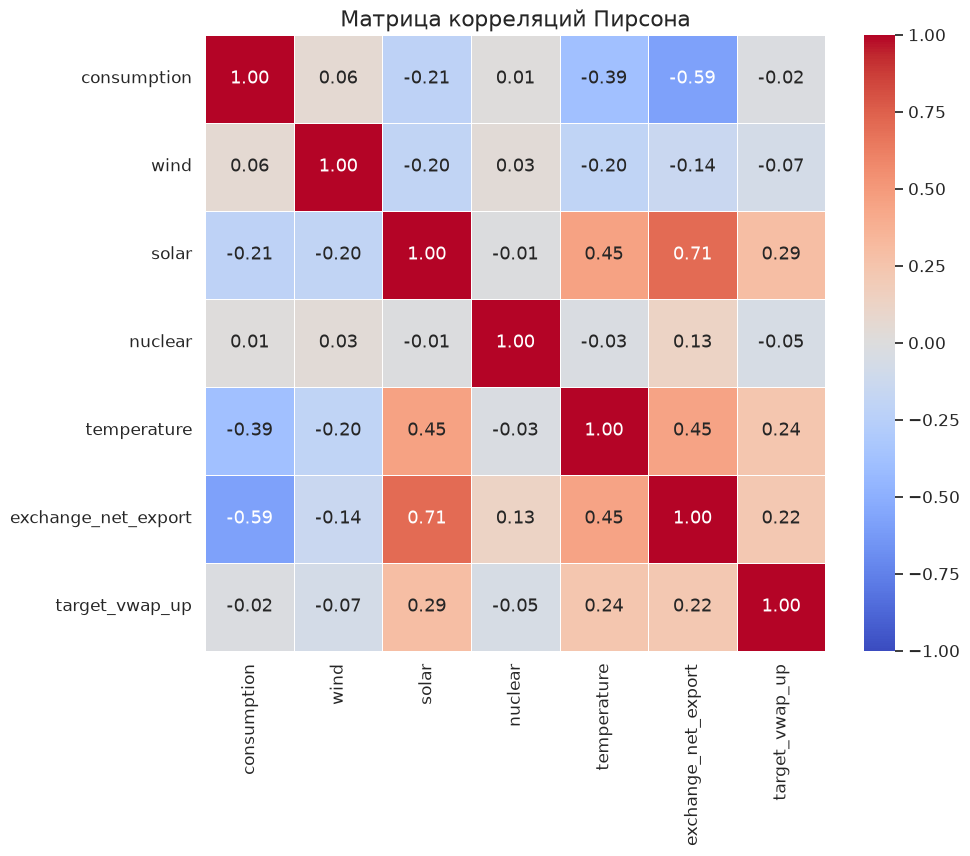

Корреляция признаков с target_vwap_up:
target_vwap_up         1.00
solar                  0.29
temperature            0.24
exchange_net_export    0.22
consumption           -0.02
nuclear               -0.05
wind                  -0.07
Name: target_vwap_up, dtype: float64


In [9]:
# Строим матрицу корреляций
plt.figure(figsize=(10, 8))
corr_matrix = df.corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", 
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Матрица корреляций Пирсона', fontsize=16)
plt.show()

# Выводим корреляцию только с целевой переменной для наглядности
print("Корреляция признаков с target_vwap_up:")
print(corr_matrix['target_vwap_up'].sort_values(ascending=False))

## 6. Анализ взаимосвязей (Корреляция)

Матрица корреляций Пирсона выявила несколько важных закономерностей:

### 🎯 Связь признаков с целевой переменной (target_vwap_up)
* **Линейной связи почти нет:** Максимальная корреляция с ценой у `solar` (0.29), затем `temperature` (0.24) и `exchange_net_export` (0.22). Остальные признаки близки к нулю. 
* **Вывод:** Простая линейная регрессия (Linear Regression) покажет плохой результат. Зависимость здесь **нелинейная и сложная** (вероятно, пороговая: "если солнце > X, то цена падает"). Это прямое обоснование использовать **градиентный бустинг (CatBoost, XGBoost, LightGBM)**, который умеет улавливать такие нелинейности.

### 🔄 Мультиколлинеарность признаков
* **Сильная связь `solar` и `exchange_net_export` (0.71):** В часы, когда светит солнце, Венгрия активно экспортирует электроэнергию (чистый экспорт растет). 
* **Обратная связь `consumption` и `exchange_net_export` (-0.59):** Чем больше энергии уходит на экспорт, тем меньше ее остается на внутреннее потребление (или наоборот).
* **Связь `temperature` и `solar` (0.45):** Летом (когда жарко) больше солнечной генерации.
* **Вывод:** Для линейных моделей (Ridge/Lasso) придется убирать один из пары (например, `exchange_net_export` или `solar`). Но для бустингов это не проблема — они отлично работают с коррелированными признаками.

## 🏁 Итоги разведочного анализа (EDA)

Мы завершили первичный анализ данных. Вот ключевые выводы, которые определят наш дальнейший пайплайн:

1. **Чистота данных:** Все основные признаки не содержат пропусков. Колонка `carbon_intensity_production` была удалена, так как изначально не содержала данных (100% NaN).
2. **Специфика целевой переменной:** Распределение цены имеет тяжелый хвост (среднее 23.4 при медиане 3.8) и **11% нулевых значений**.
3. **Метрика качества:** Для оценки моделей выбираем **MAE (Mean Absolute Error)**. Она устойчива к редким, но огромным ценовым скачкам (выбросам) и не будет «сглаживать» прогноз.
4. **Сезонность:** Выявлена сильная суточная сезонность (резкий скачок цены с 06:00 до 14:00 UTC) и аномалия выходных дней (в Сб и Вс цена в среднем выше).
5. **Проблемные периоды:** Зимой (январь–март) доля нулевых активаций достигает 37%, что требует отдельного внимания при обучении модели.
6. **Нелинейность:** Корреляции с целевой переменной слабые (максимум 0.29). Это означает, что простые линейные модели не справятся — **нужно использовать нелинейные алгоритмы (градиентные бустинги)**.

---
**Следующий этап:** Переход к генерации новых признаков (Feature Engineering) и построению первых ML-моделей.